# Clustering Analysis of Multilingual Entity Embeddings

This notebook performs comprehensive clustering analysis on entity embeddings:
- **K-Means**: Find optimal k and cluster entities
- **Hierarchical**: Analyze dendrogram and splitting patterns
- **DBSCAN**: Density-based clustering
- **HDBSCAN**: Hierarchical density-based clustering
- **Evaluation**: Compare methods using multiple metrics
- **Interpretation**: TF-IDF keywords, culture/country correlation
- **Hierarchical Analysis**: Do countries or cultures split first?

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import logging
from tqdm import tqdm

# Set up logging
logging.basicConfig(
    level=logging.INFO, format="%(asctime)s - %(name)s - %(levelname)s - %(message)s"
)

# Set random seed for reproducibility
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Plotting settings
plt.style.use("default")
sns.set_palette("husl")

print(f"✓ Random seed set to {RANDOM_SEED}")
print(f"✓ Libraries imported successfully")

✓ Random seed set to 42
✓ Libraries imported successfully


In [11]:
from src.data.database import EntityDatabase
from src.embeddings import load_cached_embeddings
from src.clustering import (
    cluster_kmeans,
    cluster_dbscan,
    cluster_hdbscan,
    cluster_hierarchical,
    find_optimal_k_kmeans,
    compare_clustering_methods,
    analyze_hierarchical_dendrogram,
    analyze_cluster_hierarchy,
    extract_tfidf_keywords,
)
from src.visualization import (
    plot_clustering_metrics_comparison,
    plot_optimal_k_analysis,
    plot_clusters_2d,
    plot_clusters_3d_interactive,
    plot_cluster_composition,
    plot_hierarchy_purity_analysis,
)
from src.analysis import (
    analyze_cluster_group_correlation,
    analyze_cluster_purity,
    test_hierarchical_split_order,
    calculate_contingency_table,
)

## Load Data

In [12]:
df = pd.read_csv("../data/experiment/selected_entities.csv")
print(f"✓ Loaded {len(df)} selected entities")
print(f"  Columns: {df.columns.tolist()}")

# Display basic statistics
print("\n" + "=" * 80)
print("DATA OVERVIEW")
print("=" * 80)
print(f"Total entities: {len(df)}")
print(f"\nEntity types: {df['type'].value_counts().to_dict()}")
print(f"\nCultures: {df['culture'].value_counts().to_dict()}")
print(f"\nTop 10 countries: {df['country'].value_counts().head(10).to_dict()}")

✓ Loaded 23007 selected entities
  Columns: ['id', 'wikidata_id', 'type', 'culture', 'country', 'created_at', 'label', 'labels', 'num_wikipedia_languages', 'birth_year', 'occupation_en', 'occupation_fr', 'occupation_ar', 'sex', 'occupation_group']

DATA OVERVIEW
Total entities: 23007

Entity types: {'person': 23007}

Cultures: {'Western': 6010, 'Latin American': 5150, 'East Asian': 4096, 'Arabic': 3714, 'African': 2329, 'South Asian': 1247, 'Southeast Asian': 461}

Top 10 countries: {'Japan': 1666, 'United States': 1650, 'Brazil': 1589, 'Morocco': 1514, 'Germany': 1487, 'France': 1480, 'Argentina': 1451, 'United Kingdom': 1393, 'Egypt': 1275, 'Mexico': 1215}


## loading embeddings

In [13]:
# Load cached embeddings (choose which language or combined)
# Options: 'en', 'fr', 'ar', or 'combined'
language_choice = "ar"  # Change as needed
cache_dir = Path('../data/embeddings')
model_name = "intfloat_multilingual-e5-large"

embeddings_data = load_cached_embeddings(
        language= language_choice,
        model_name=model_name,
        save_dir=cache_dir,
        text_type='content'
    )

embeddings = embeddings_data['embeddings']

print(f"✓ Loaded embeddings: {embeddings.shape}")
print(f"  Language: {language_choice}")
print(f"  Embedding dimension: {embeddings.shape[1]}")

# Check for NaN or Inf
if np.any(np.isnan(embeddings)):
    print("⚠ Warning: NaN values detected in embeddings")
if np.any(np.isinf(embeddings)):
    print("⚠ Warning: Inf values detected in embeddings")

2026-01-09 16:18:19,372 - src.embeddings.text_embedder - INFO - Loading cached embeddings from ../data/embeddings/embeddings_ar_content_intfloat_multilingual-e5-large.pkl
2026-01-09 16:18:19,395 - src.embeddings.text_embedder - INFO - Loaded embeddings shape: (23007, 1024)
2026-01-09 16:18:19,396 - src.embeddings.text_embedder - INFO - Number of entities: 23007


✓ Loaded embeddings: (23007, 1024)
  Language: ar
  Embedding dimension: 1024


In [14]:
embeddings.mean(axis=1)

array([-0.0008187 , -0.00079915, -0.00080896, ..., -0.0007833 ,
       -0.00077732, -0.00077158], shape=(23007,), dtype=float32)

In [15]:
# ============================================================================
# CELL 6: Normalize Embeddings
# ============================================================================
from sklearn.preprocessing import normalize

embeddings_normalized = normalize(embeddings, norm='l2', axis=1)

print(f"✓ Embeddings normalized")

✓ Embeddings normalized


✓ PCA applied: 100 components
  Variance explained: 67.45%
  Variance by first 10 components: 24.16%


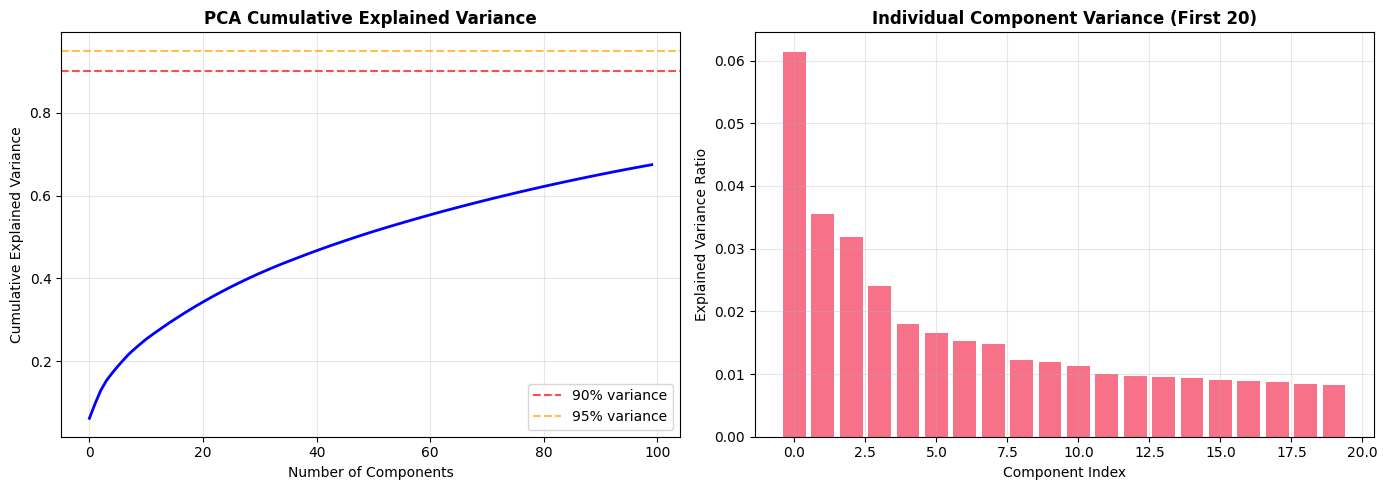

✓ Variance plot saved


In [16]:
# ============================================================================
# CELL 7: PCA Dimensionality Reduction
# ============================================================================
from sklearn.decomposition import PCA

# Choose number of components (50 or 100)
n_components = 100  # or 100

pca = PCA(
    n_components=min(n_components, embeddings_normalized.shape[1]),
    random_state=RANDOM_SEED,
)
embeddings_pca = pca.fit_transform(embeddings_normalized)

print(f"✓ PCA applied: {embeddings_pca.shape[1]} components")
print(f"  Variance explained: {pca.explained_variance_ratio_.sum():.2%}")
print(
    f"  Variance by first 10 components: {pca.explained_variance_ratio_[:10].sum():.2%}"
)

# Plot explained variance
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Cumulative variance
ax = axes[0]
ax.plot(np.cumsum(pca.explained_variance_ratio_), "b-", linewidth=2)
ax.axhline(0.9, color="r", linestyle="--", alpha=0.7, label="90% variance")
ax.axhline(0.95, color="orange", linestyle="--", alpha=0.7, label="95% variance")
ax.set_xlabel("Number of Components")
ax.set_ylabel("Cumulative Explained Variance")
ax.set_title("PCA Cumulative Explained Variance", fontweight="bold")
ax.legend()
ax.grid(True, alpha=0.3)

# Individual variance
ax = axes[1]
ax.bar(
    range(min(20, len(pca.explained_variance_ratio_))),
    pca.explained_variance_ratio_[:20],
)
ax.set_xlabel("Component Index")
ax.set_ylabel("Explained Variance Ratio")
ax.set_title("Individual Component Variance (First 20)", fontweight="bold")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
print("✓ Variance plot saved")


In [17]:
# normalizing pca embeddings

#embeddings_pca = normalize(embeddings_pca, norm='l2', axis=1)


2026-01-09 16:18:21,445 - src.clustering.cluster_methods - INFO - Finding optimal k in range range(2, 100)



FINDING OPTIMAL K FOR K-MEANS


2026-01-09 16:18:24,219 - src.clustering.cluster_methods - INFO - k=2: silhouette=0.137, DB=3.476, CH=1828.8
2026-01-09 16:18:26,923 - src.clustering.cluster_methods - INFO - k=3: silhouette=0.121, DB=3.824, CH=1399.1
2026-01-09 16:18:29,623 - src.clustering.cluster_methods - INFO - k=4: silhouette=0.121, DB=3.546, CH=1190.9
2026-01-09 16:18:32,297 - src.clustering.cluster_methods - INFO - k=5: silhouette=0.118, DB=3.513, CH=1038.0
2026-01-09 16:18:35,032 - src.clustering.cluster_methods - INFO - k=6: silhouette=0.102, DB=3.640, CH=919.9
2026-01-09 16:18:37,772 - src.clustering.cluster_methods - INFO - k=7: silhouette=0.092, DB=3.785, CH=827.8
2026-01-09 16:18:40,679 - src.clustering.cluster_methods - INFO - k=8: silhouette=0.093, DB=3.672, CH=759.2
2026-01-09 16:18:43,558 - src.clustering.cluster_methods - INFO - k=9: silhouette=0.088, DB=3.672, CH=699.4
2026-01-09 16:18:46,421 - src.clustering.cluster_methods - INFO - k=10: silhouette=0.099, DB=3.417, CH=659.6
2026-01-09 16:18:49,436

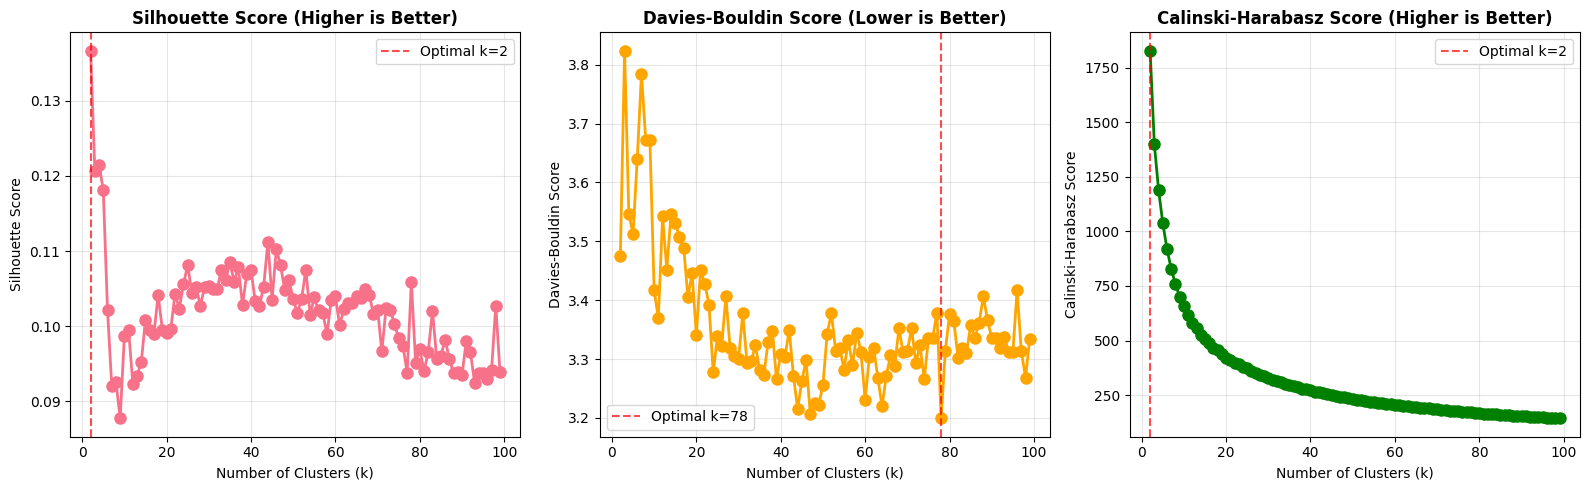


Optimal k values:
  silhouette: k=2
  davies_bouldin: k=78
  calinski_harabasz: k=2

✓ Using k=2 for K-Means


In [18]:
# ============================================================================
# CELL 8: Find Optimal K for K-Means
# ============================================================================
print("\n" + "=" * 80)
print("FINDING OPTIMAL K FOR K-MEANS")
print("=" * 80)

k_range = range(2, 100, 1)
optimal_k_results = find_optimal_k_kmeans(
    embeddings_pca, k_range=k_range, random_state=RANDOM_SEED
)

# Plot optimal k analysis
fig = plot_optimal_k_analysis(optimal_k_results, figsize=(16, 5))
plt.show()

print("\nOptimal k values:")
for metric, k in optimal_k_results["optimal_k"].items():
    print(f"  {metric}: k={k}")

# Choose optimal k (you can adjust based on results)
optimal_k = optimal_k_results["optimal_k"]["silhouette"]
print(f"\n✓ Using k={optimal_k} for K-Means")


In [19]:
# ============================================================================
# CELL 9: Perform K-Means Clustering
# ============================================================================
print("\n" + "=" * 80)
print("K-MEANS CLUSTERING")
print("=" * 80)

labels_kmeans = cluster_kmeans(
    embeddings_pca, n_clusters=optimal_k, random_state=RANDOM_SEED
)
df["cluster_kmeans"] = labels_kmeans

print(f"✓ K-Means clustering complete")
print(f"  Number of clusters: {len(set(labels_kmeans))}")
print(f"\nCluster sizes:")
for cluster_id in sorted(set(labels_kmeans)):
    count = (labels_kmeans == cluster_id).sum()
    print(
        f"  Cluster {cluster_id}: {count} entities ({100*count/len(labels_kmeans):.1f}%)"
    )


2026-01-09 16:24:40,815 - src.clustering.cluster_methods - INFO - K-Means clustering: 2 clusters
2026-01-09 16:24:40,912 - src.clustering.cluster_methods - INFO - K-Means complete: 2 unique clusters



K-MEANS CLUSTERING
✓ K-Means clustering complete
  Number of clusters: 2

Cluster sizes:
  Cluster 0: 13550 entities (58.9%)
  Cluster 1: 9457 entities (41.1%)


In [20]:
# ============================================================================
# CELL 10: Hierarchical Clustering
# ============================================================================
print("\n" + "=" * 80)
print("HIERARCHICAL CLUSTERING")
print("=" * 80)

# Try different linkage methods
linkage_methods = ["ward", "complete", "average"]
hierarchical_results = {}

for method in linkage_methods:
    print(f"\nTrying {method} linkage...")
    labels_hier = cluster_hierarchical(
        embeddings_pca, n_clusters=optimal_k, linkage=method, metric="euclidean"
    )
    hierarchical_results[method] = labels_hier
    df[f"cluster_hierarchical_{method}"] = labels_hier

# Use ward for main analysis
labels_hierarchical = hierarchical_results["ward"]
df["cluster_hierarchical"] = labels_hierarchical

print(f"\n✓ Hierarchical clustering complete")
print(f"  Using 'ward' linkage for main analysis")
print(f"  Number of clusters: {len(set(labels_hierarchical))}")

2026-01-09 16:24:40,918 - src.clustering.cluster_methods - INFO - Hierarchical clustering: 2 clusters, linkage=ward, metric=euclidean



HIERARCHICAL CLUSTERING

Trying ward linkage...


2026-01-09 16:24:55,727 - src.clustering.cluster_methods - INFO - Hierarchical complete: 2 unique clusters
2026-01-09 16:24:55,728 - src.clustering.cluster_methods - INFO - Hierarchical clustering: 2 clusters, linkage=complete, metric=euclidean



Trying complete linkage...


2026-01-09 16:25:09,636 - src.clustering.cluster_methods - INFO - Hierarchical complete: 2 unique clusters
2026-01-09 16:25:09,637 - src.clustering.cluster_methods - INFO - Hierarchical clustering: 2 clusters, linkage=average, metric=euclidean



Trying average linkage...


2026-01-09 16:25:22,971 - src.clustering.cluster_methods - INFO - Hierarchical complete: 2 unique clusters



✓ Hierarchical clustering complete
  Using 'ward' linkage for main analysis
  Number of clusters: 2


2026-01-09 16:25:22,976 - src.clustering.cluster_methods - INFO - Creating dendrogram: method=ward, metric=euclidean
2026-01-09 16:25:22,977 - src.clustering.cluster_methods - INFO - Sampling 1000 points from 23007
2026-01-09 16:25:23,003 - src.clustering.cluster_methods - INFO - Dendrogram created



DENDROGRAM VISUALIZATION


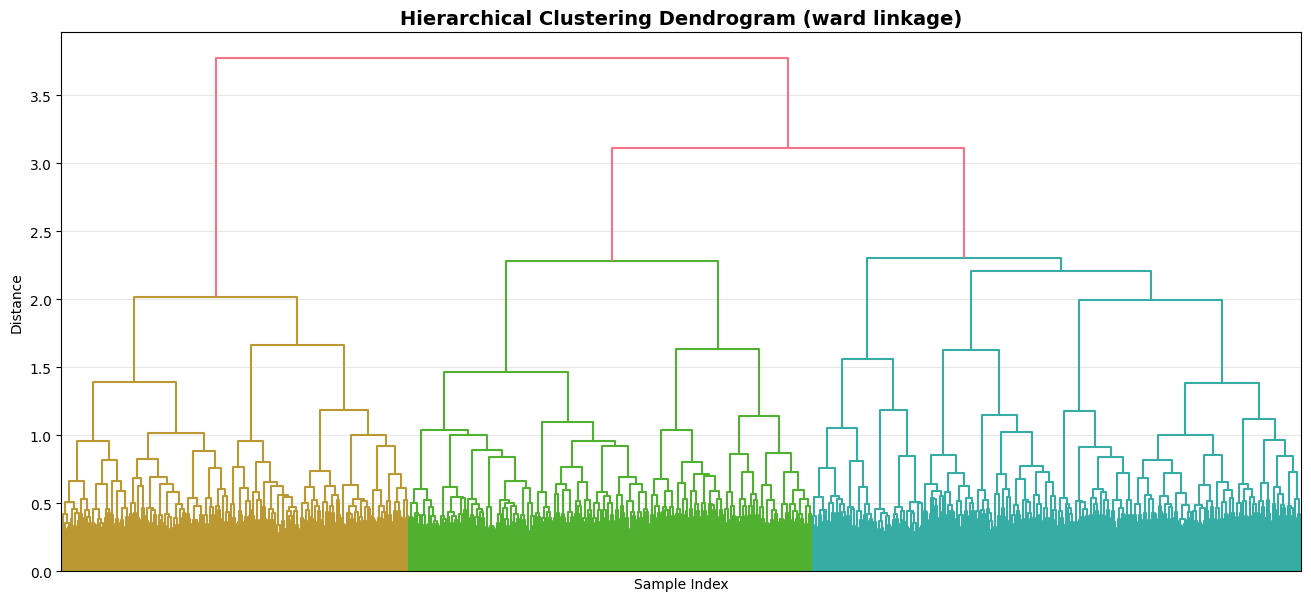

In [21]:
# ============================================================================
# CELL 11: Dendrogram Analysis
# ============================================================================
print("\n" + "=" * 80)
print("DENDROGRAM VISUALIZATION")
print("=" * 80)

# Create dendrogram (sample if too many points)
linkage_matrix, fig = analyze_hierarchical_dendrogram(
    embeddings_pca, method="ward", metric="euclidean", max_samples=1000, figsize=(16, 7)
)
plt.show()




DBSCAN CLUSTERING


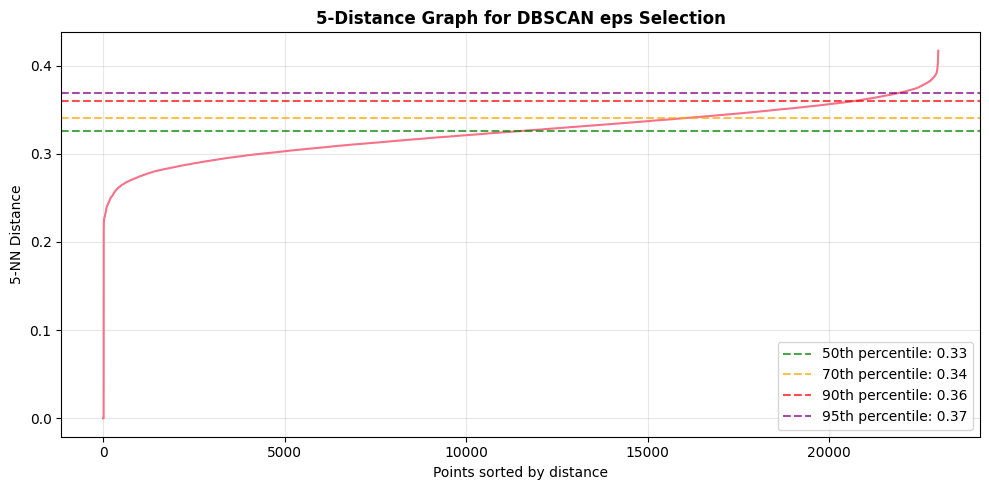

2026-01-09 16:25:23,416 - src.clustering.cluster_methods - INFO - DBSCAN clustering: eps=0.05, min_samples=5



Trying different eps values...
------------------------------------------------------------


2026-01-09 16:25:25,390 - src.clustering.cluster_methods - INFO - DBSCAN complete: 3 clusters, 22990 noise points
2026-01-09 16:25:25,392 - src.clustering.cluster_methods - INFO - DBSCAN clustering: eps=0.1, min_samples=5


eps=0.050: 3 clusters, 22990 noise (99.9%)


2026-01-09 16:25:27,374 - src.clustering.cluster_methods - INFO - DBSCAN complete: 3 clusters, 22990 noise points
2026-01-09 16:25:27,375 - src.clustering.cluster_methods - INFO - DBSCAN clustering: eps=0.15, min_samples=5


...

eps=0.500: 1 clusters, 177 noise (0.8%)


2026-01-09 16:25:41,469 - src.clustering.cluster_methods - INFO - DBSCAN complete: 1 clusters, 23 noise points
2026-01-09 16:25:41,471 - src.clustering.cluster_methods - INFO - DBSCAN clustering: eps=0.45, min_samples=5


eps=0.550: 1 clusters, 23 noise (0.1%)

✓ Selected eps: 0.450
  Using min_samples: 5


2026-01-09 16:25:43,455 - src.clustering.cluster_methods - INFO - DBSCAN complete: 4 clusters, 1380 noise points



✓ DBSCAN clustering complete
  Number of clusters: 4
  Noise points: 1380 (6.0%)


In [22]:
# ============================================================================
# CELL 12: DBSCAN Clustering
# ============================================================================
print("\n" + "=" * 80)
print("DBSCAN CLUSTERING")
print("=" * 80)

from sklearn.neighbors import NearestNeighbors

# Calculate k-distance for eps selection
k = 5
nbrs = NearestNeighbors(n_neighbors=k).fit(embeddings_pca)
distances, indices = nbrs.kneighbors(embeddings_pca)
distances = np.sort(distances[:, -1])

# Plot k-distance graph
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(distances)
ax.set_xlabel("Points sorted by distance")
ax.set_ylabel(f"{k}-NN Distance")
ax.set_title(f"{k}-Distance Graph for DBSCAN eps Selection", fontweight="bold")
ax.grid(True, alpha=0.3)

# Add reference lines for different percentiles
percentiles = [50, 70, 90, 95]
colors = ['green', 'orange', 'red', 'purple']
for p, color in zip(percentiles, colors):
    eps_p = np.percentile(distances, p)
    ax.axhline(eps_p, color=color, linestyle='--', alpha=0.7,
               label=f'{p}th percentile: {eps_p:.2f}')

ax.legend()
plt.tight_layout()
plt.show()

# Try different eps values to find good clustering
print("\nTrying different eps values...")
print("-" * 60)

eps_candidates = [
    np.percentile(distances, 50),  # Median
    np.percentile(distances, 60),
    np.percentile(distances, 70),
    np.percentile(distances, 80),
]

eps_candidates = [0.05, 0.1, 0.15, 0.2, 0.3, 0.4, 0.45, 0.5, 0.55]
min_samples = 5
best_eps = None
best_n_clusters = 0

for eps_value in eps_candidates:
    labels_test = cluster_dbscan(embeddings_pca, eps=eps_value, min_samples=min_samples)
    n_clusters = len(set(labels_test)) - (1 if -1 in labels_test else 0)
    n_noise = list(labels_test).count(-1)

    print(f"eps={eps_value:.3f}: {n_clusters} clusters, "
          f"{n_noise} noise ({100*n_noise/len(labels_test):.1f}%)")

    # Choose eps with reasonable number of clusters (2-20) and not too much noise
    if 2 <= n_clusters <= 20 and n_noise < 0.5 * len(labels_test):
        if n_clusters > best_n_clusters:
            best_eps = eps_value
            best_n_clusters = n_clusters

# If no good eps found, use a manual value
if best_eps is None:
    print("\n⚠️  No suitable eps found automatically. Using manual value.")
    # Rule of thumb: try eps around the "elbow" of the k-distance plot
    # Usually between 50th-70th percentile
    best_eps = np.percentile(distances, 60)
    print(f"   Trying eps={best_eps:.3f}")

print(f"\n✓ Selected eps: {best_eps:.3f}")
print(f"  Using min_samples: {min_samples}")

# Final DBSCAN with best eps
labels_dbscan = cluster_dbscan(embeddings_pca, eps=best_eps, min_samples=min_samples)
df["cluster_dbscan"] = labels_dbscan

n_clusters = len(set(labels_dbscan)) - (1 if -1 in labels_dbscan else 0)
n_noise = list(labels_dbscan).count(-1)

print(f"\n✓ DBSCAN clustering complete")
print(f"  Number of clusters: {n_clusters}")
print(f"  Noise points: {n_noise} ({100*n_noise/len(labels_dbscan):.1f}%)")

# Warning if still problematic
if n_clusters == 1:
    print("\n⚠️  WARNING: Still only 1 cluster!")
    print("   DBSCAN may not be suitable for this data.")
    print("   Consider using HDBSCAN instead (Cell 13).")
elif n_noise > 0.5 * len(labels_dbscan):
    print("\n⚠️  WARNING: Over 50% noise points!")
    print("   Try increasing eps or decreasing min_samples.")

In [23]:
# ============================================================================
# CELL 13: HDBSCAN Clustering
# ============================================================================
print("\n" + "=" * 80)
print("HDBSCAN CLUSTERING")
print("=" * 80)

# Try different parameter combinations
print("Testing different HDBSCAN parameters...")
print("-" * 60)

# Parameter candidates
min_cluster_size_candidates = [
    max(int(len(df) * 0.005), 5),  # 0.5% of data
    max(int(len(df) * 0.01), 10),  # 1% of data
    max(int(len(df) * 0.02), 15),  # 2% of data
]

min_samples_candidates = [1, 3, 5]

best_params = None
best_n_clusters = 0
best_noise_ratio = 1.0
results = []

for min_cluster_size in min_cluster_size_candidates:
    for min_samples_val in min_samples_candidates:
        labels_test = cluster_hdbscan(
            embeddings_pca,
            min_cluster_size=min_cluster_size,
            min_samples=min_samples_val
        )

        n_clusters = len(set(labels_test)) - (1 if -1 in labels_test else 0)
        n_noise = list(labels_test).count(-1)
        noise_ratio = n_noise / len(labels_test)

        print(f"min_cluster_size={min_cluster_size}, min_samples={min_samples_val}: "
              f"{n_clusters} clusters, {n_noise} noise ({100*noise_ratio:.1f}%)")

        results.append({
            'min_cluster_size': min_cluster_size,
            'min_samples': min_samples_val,
            'n_clusters': n_clusters,
            'noise_ratio': noise_ratio
        })

        # Choose parameters with:
        # 1. Reasonable number of clusters (2-20)
        # 2. Less than 30% noise (more lenient than 50%)
        # 3. Maximize number of clusters while keeping noise low
        if (2 <= n_clusters <= 20 and
            noise_ratio < 0.3 and
            n_clusters > best_n_clusters):
            best_params = (min_cluster_size, min_samples_val)
            best_n_clusters = n_clusters
            best_noise_ratio = noise_ratio

# If no good params found with <30% noise, accept up to 40%
if best_params is None:
    print("\n⚠️  No params with <30% noise. Trying <40% noise...")
    for result in results:
        if (2 <= result['n_clusters'] <= 20 and
            result['noise_ratio'] < 0.4 and
            result['n_clusters'] > best_n_clusters):
            best_params = (result['min_cluster_size'], result['min_samples'])
            best_n_clusters = result['n_clusters']
            best_noise_ratio = result['noise_ratio']

# If still no good params, use most lenient
if best_params is None:
    print("\n⚠️  Still no suitable params. Using most lenient settings.")
    best_params = (min_cluster_size_candidates[0], min_samples_candidates[0])
    print(f"   Defaulting to min_cluster_size={best_params[0]}, min_samples={best_params[1]}")

min_cluster_size, min_samples_hdbscan = best_params
print(f"\n✓ Selected parameters:")
print(f"  min_cluster_size: {min_cluster_size}")
print(f"  min_samples: {min_samples_hdbscan}")
print(f"  Expected: ~{best_n_clusters} clusters, ~{100*best_noise_ratio:.1f}% noise")

# Final HDBSCAN with best parameters
labels_hdbscan = cluster_hdbscan(
    embeddings_pca,
    min_cluster_size=min_cluster_size,
    min_samples=min_samples_hdbscan
)
df["cluster_hdbscan"] = labels_hdbscan

n_clusters = len(set(labels_hdbscan)) - (1 if -1 in labels_hdbscan else 0)
n_noise = list(labels_hdbscan).count(-1)

print(f"\n✓ HDBSCAN clustering complete")
print(f"  Number of clusters: {n_clusters}")
print(f"  Noise points: {n_noise} ({100*n_noise/len(labels_hdbscan):.1f}%)")

# Interpretation
if n_noise > 0.4 * len(labels_hdbscan):
    print("\n⚠️  WARNING: Over 40% noise points!")
    print("   HDBSCAN may not be suitable for this embedding space.")
    print("   This suggests uniform density (common for embeddings).")
    print("   → Recommendation: Focus on K-Means or Hierarchical clustering results.")
elif n_clusters < 2:
    print("\n⚠️  WARNING: Less than 2 clusters found!")
    print("   HDBSCAN couldn't find distinct density-based clusters.")
    print("   → Recommendation: Use K-Means or Hierarchical clustering instead.")
else:
    print(f"\n✓ HDBSCAN found {n_clusters} density-based clusters")
    print(f"   Noise ratio: {100*n_noise/len(labels_hdbscan):.1f}%")

2026-01-09 16:25:43,464 - src.clustering.cluster_methods - INFO - HDBSCAN clustering: min_cluster_size=115, min_samples=1



HDBSCAN CLUSTERING
Testing different HDBSCAN parameters...
------------------------------------------------------------


2026-01-09 16:25:52,170 - src.clustering.cluster_methods - INFO - HDBSCAN complete: 13 clusters, 18060 noise points
2026-01-09 16:25:52,172 - src.clustering.cluster_methods - INFO - HDBSCAN clustering: min_cluster_size=115, min_samples=3


min_cluster_size=115, min_samples=1: 13 clusters, 18060 noise (78.5%)


2026-01-09 16:26:33,310 - src.clustering.cluster_methods - INFO - HDBSCAN complete: 9 clusters, 18767 noise points
2026-01-09 16:26:33,312 - src.clustering.cluster_methods - INFO - HDBSCAN clustering: min_cluster_size=115, min_samples=5


...

min_cluster_size=460, min_samples=3: 4 clusters, 18265 noise (79.4%)


2026-01-09 16:29:56,554 - src.clustering.cluster_methods - INFO - HDBSCAN complete: 2 clusters, 18156 noise points
2026-01-09 16:29:56,555 - src.clustering.cluster_methods - INFO - HDBSCAN clustering: min_cluster_size=115, min_samples=1


min_cluster_size=460, min_samples=5: 2 clusters, 18156 noise (78.9%)

⚠️  No params with <30% noise. Trying <40% noise...

⚠️  Still no suitable params. Using most lenient settings.
   Defaulting to min_cluster_size=115, min_samples=1

✓ Selected parameters:
  min_cluster_size: 115
  min_samples: 1
  Expected: ~0 clusters, ~100.0% noise


2026-01-09 16:30:05,200 - src.clustering.cluster_methods - INFO - HDBSCAN complete: 13 clusters, 18060 noise points



✓ HDBSCAN clustering complete
  Number of clusters: 13
  Noise points: 18060 (78.5%)

⚠️  WARNING: Over 40% noise points!
   HDBSCAN may not be suitable for this embedding space.
   This suggests uniform density (common for embeddings).
   → Recommendation: Focus on K-Means or Hierarchical clustering results.


2026-01-09 16:30:05,206 - src.clustering.cluster_methods - INFO - Comparing 4 clustering methods



COMPARING CLUSTERING METHODS


2026-01-09 16:30:13,499 - src.clustering.cluster_methods - INFO - Comparison complete for 4 methods



Comparison Results:
                method  n_clusters  n_noise  noise_pct  silhouette  davies_bouldin  calinski_harabasz  min_cluster_size  max_cluster_size  avg_cluster_size  std_cluster_size
0              K-Means           2        0   0.000000    0.136620        3.475811        1828.846802              9457             13550      11503.500000       2046.500000
1  Hierarchical (Ward)           2        0   0.000000    0.094843        4.105918        1221.408081              8258             14749      11503.500000       3245.500000
2               DBSCAN           4     1380   5.998174   -0.088723        1.905591           4.121944                 4             21609       5406.750000       9354.373506
3              HDBSCAN          13    18060  78.497848    0.193878        2.375025         245.489853               121               812        380.538462        229.588801


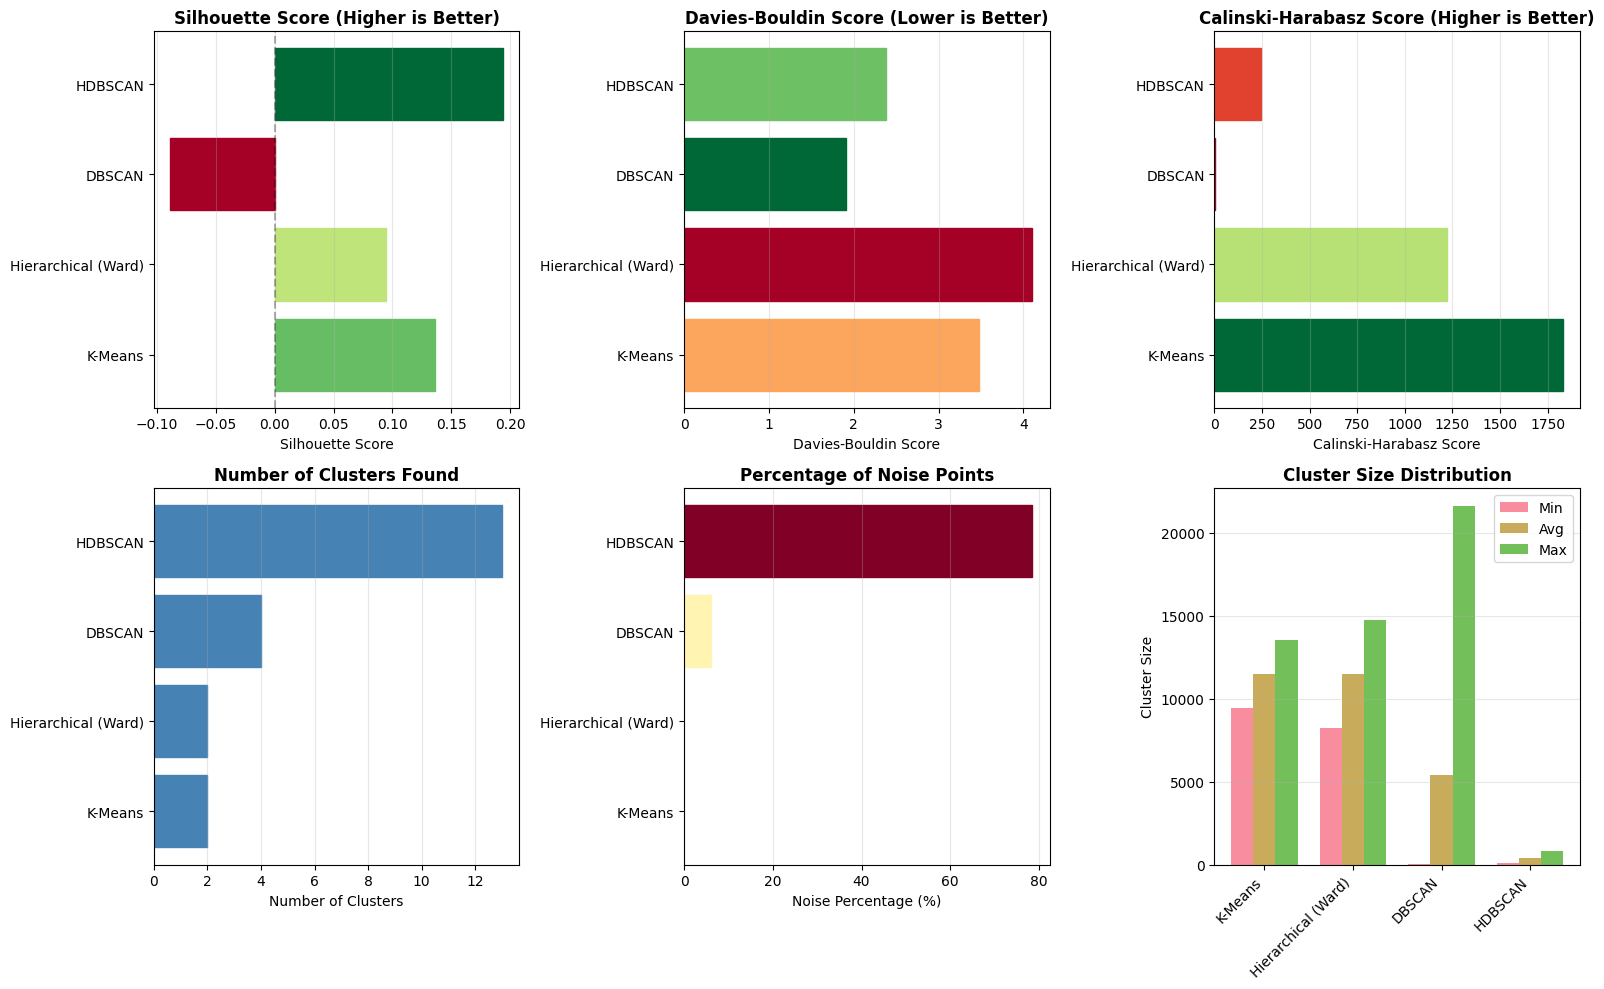


✓ Comparison complete and saved


In [24]:
# ============================================================================
# CELL 14: Compare Clustering Methods
# ============================================================================
print("\n" + "=" * 80)
print("COMPARING CLUSTERING METHODS")
print("=" * 80)

labels_dict = {
    "K-Means": labels_kmeans,
    "Hierarchical (Ward)": labels_hierarchical,
    "DBSCAN": labels_dbscan,
    "HDBSCAN": labels_hdbscan,
}

comparison_df = compare_clustering_methods(
    embeddings_pca, labels_dict, exclude_noise=True
)

print("\nComparison Results:")
print(comparison_df.to_string())

# Visualize comparison
fig = plot_clustering_metrics_comparison(comparison_df, figsize=(16, 10))
plt.show()

print("\n✓ Comparison complete and saved")



2D VISUALIZATION (t-SNE)
Computing t-SNE projection...


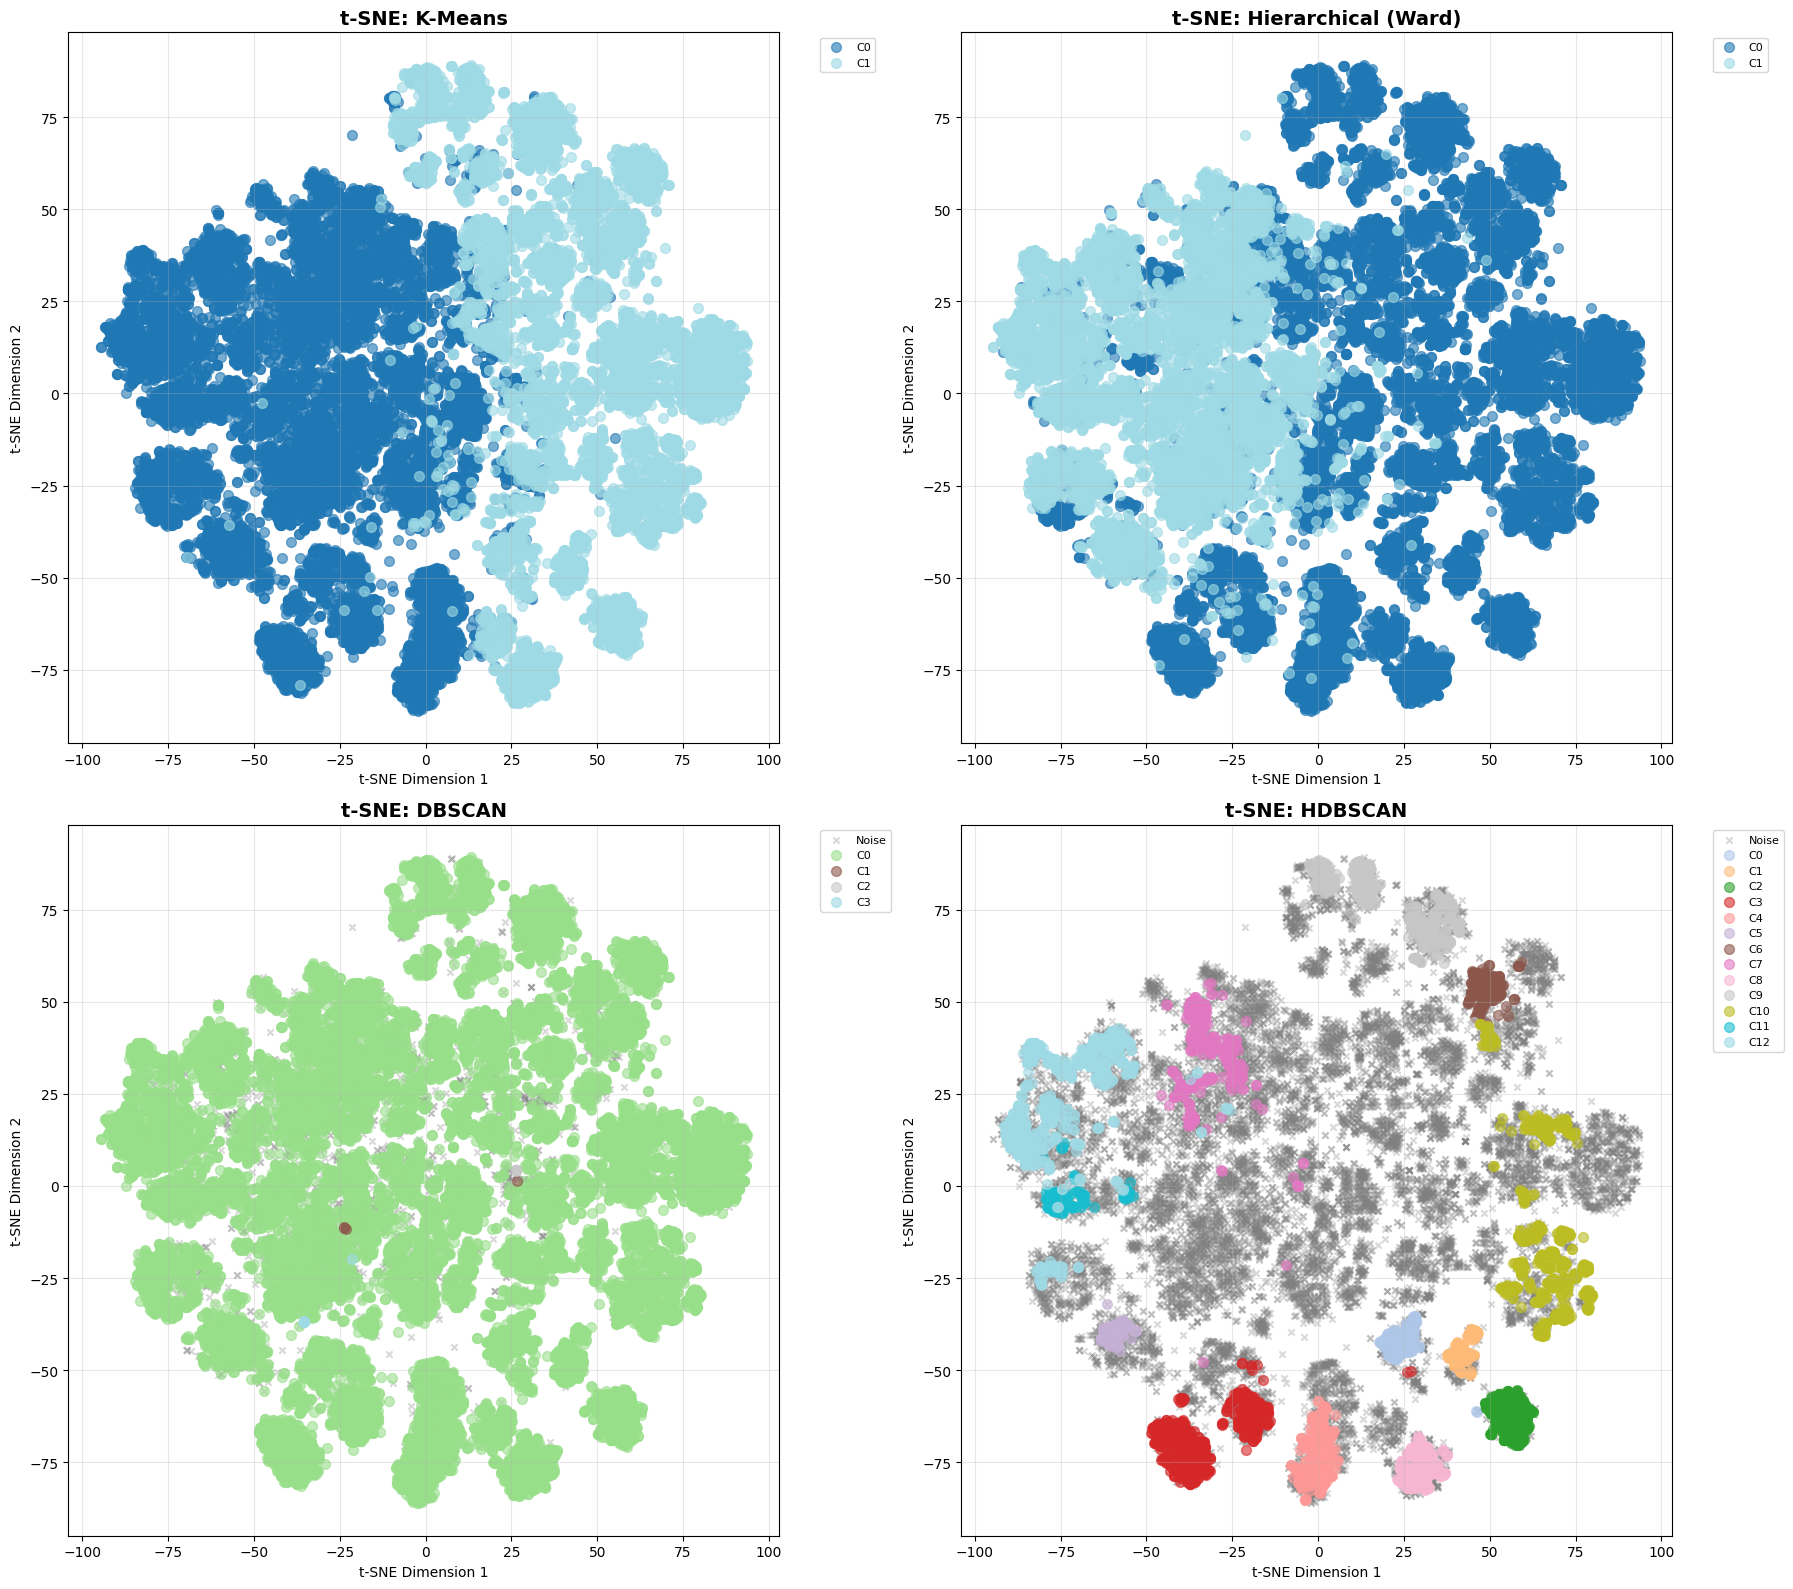

✓ t-SNE visualization complete


In [25]:
# ============================================================================
# CELL 15: 2D Visualization with t-SNE
# ============================================================================
print("\n" + "=" * 80)
print("2D VISUALIZATION (t-SNE)")
print("=" * 80)

from sklearn.manifold import TSNE

print("Computing t-SNE projection...")
tsne = TSNE(n_components=2, random_state=RANDOM_SEED, perplexity=30)
embeddings_tsne = tsne.fit_transform(embeddings_pca)

# Plot each clustering method
fig, axes = plt.subplots(2, 2, figsize=(18, 16))

methods = ["K-Means", "Hierarchical (Ward)", "DBSCAN", "HDBSCAN"]
labels_list = [labels_kmeans, labels_hierarchical, labels_dbscan, labels_hdbscan]

for idx, (method, labels) in enumerate(zip(methods, labels_list)):
    ax = axes[idx // 2, idx % 2]

    unique_labels = sorted(set(labels))
    colors = plt.cm.tab20(np.linspace(0, 1, len(unique_labels)))

    for label, color in zip(unique_labels, colors):
        mask = labels == label
        if label == -1:
            ax.scatter(
                embeddings_tsne[mask, 0],
                embeddings_tsne[mask, 1],
                c="gray",
                s=20,
                alpha=0.3,
                label="Noise",
                marker="x",
            )
        else:
            ax.scatter(
                embeddings_tsne[mask, 0],
                embeddings_tsne[mask, 1],
                c=[color],
                s=50,
                alpha=0.6,
                label=f"C{label}",
            )

    ax.set_title(f"t-SNE: {method}", fontsize=14, fontweight="bold")
    ax.set_xlabel("t-SNE Dimension 1")
    ax.set_ylabel("t-SNE Dimension 2")
    ax.legend(bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=8)
    ax.grid(True, alpha=0.3)

plt.tight_layout()

plt.show()

print("✓ t-SNE visualization complete")


2D VISUALIZATION (UMAP)
Computing UMAP projection...


/home/khaledbouabdallah/Projects/llm_grouping_loss_INRIA/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/khaledbouabdallah/Projects/llm_grouping_loss_INRIA/.venv/lib/python3.13/site-packages/numba/np/ufunc/parallel.py:373: NumbaWarning: The TBB threading layer requires TBB version 2021 update 6 or later i.e., TBB_INTERFACE_VERSION >= 12060. Found TBB_INTERFACE_VERSION = 12050. The TBB threading layer is disabled.
  warnings.warn(problem)


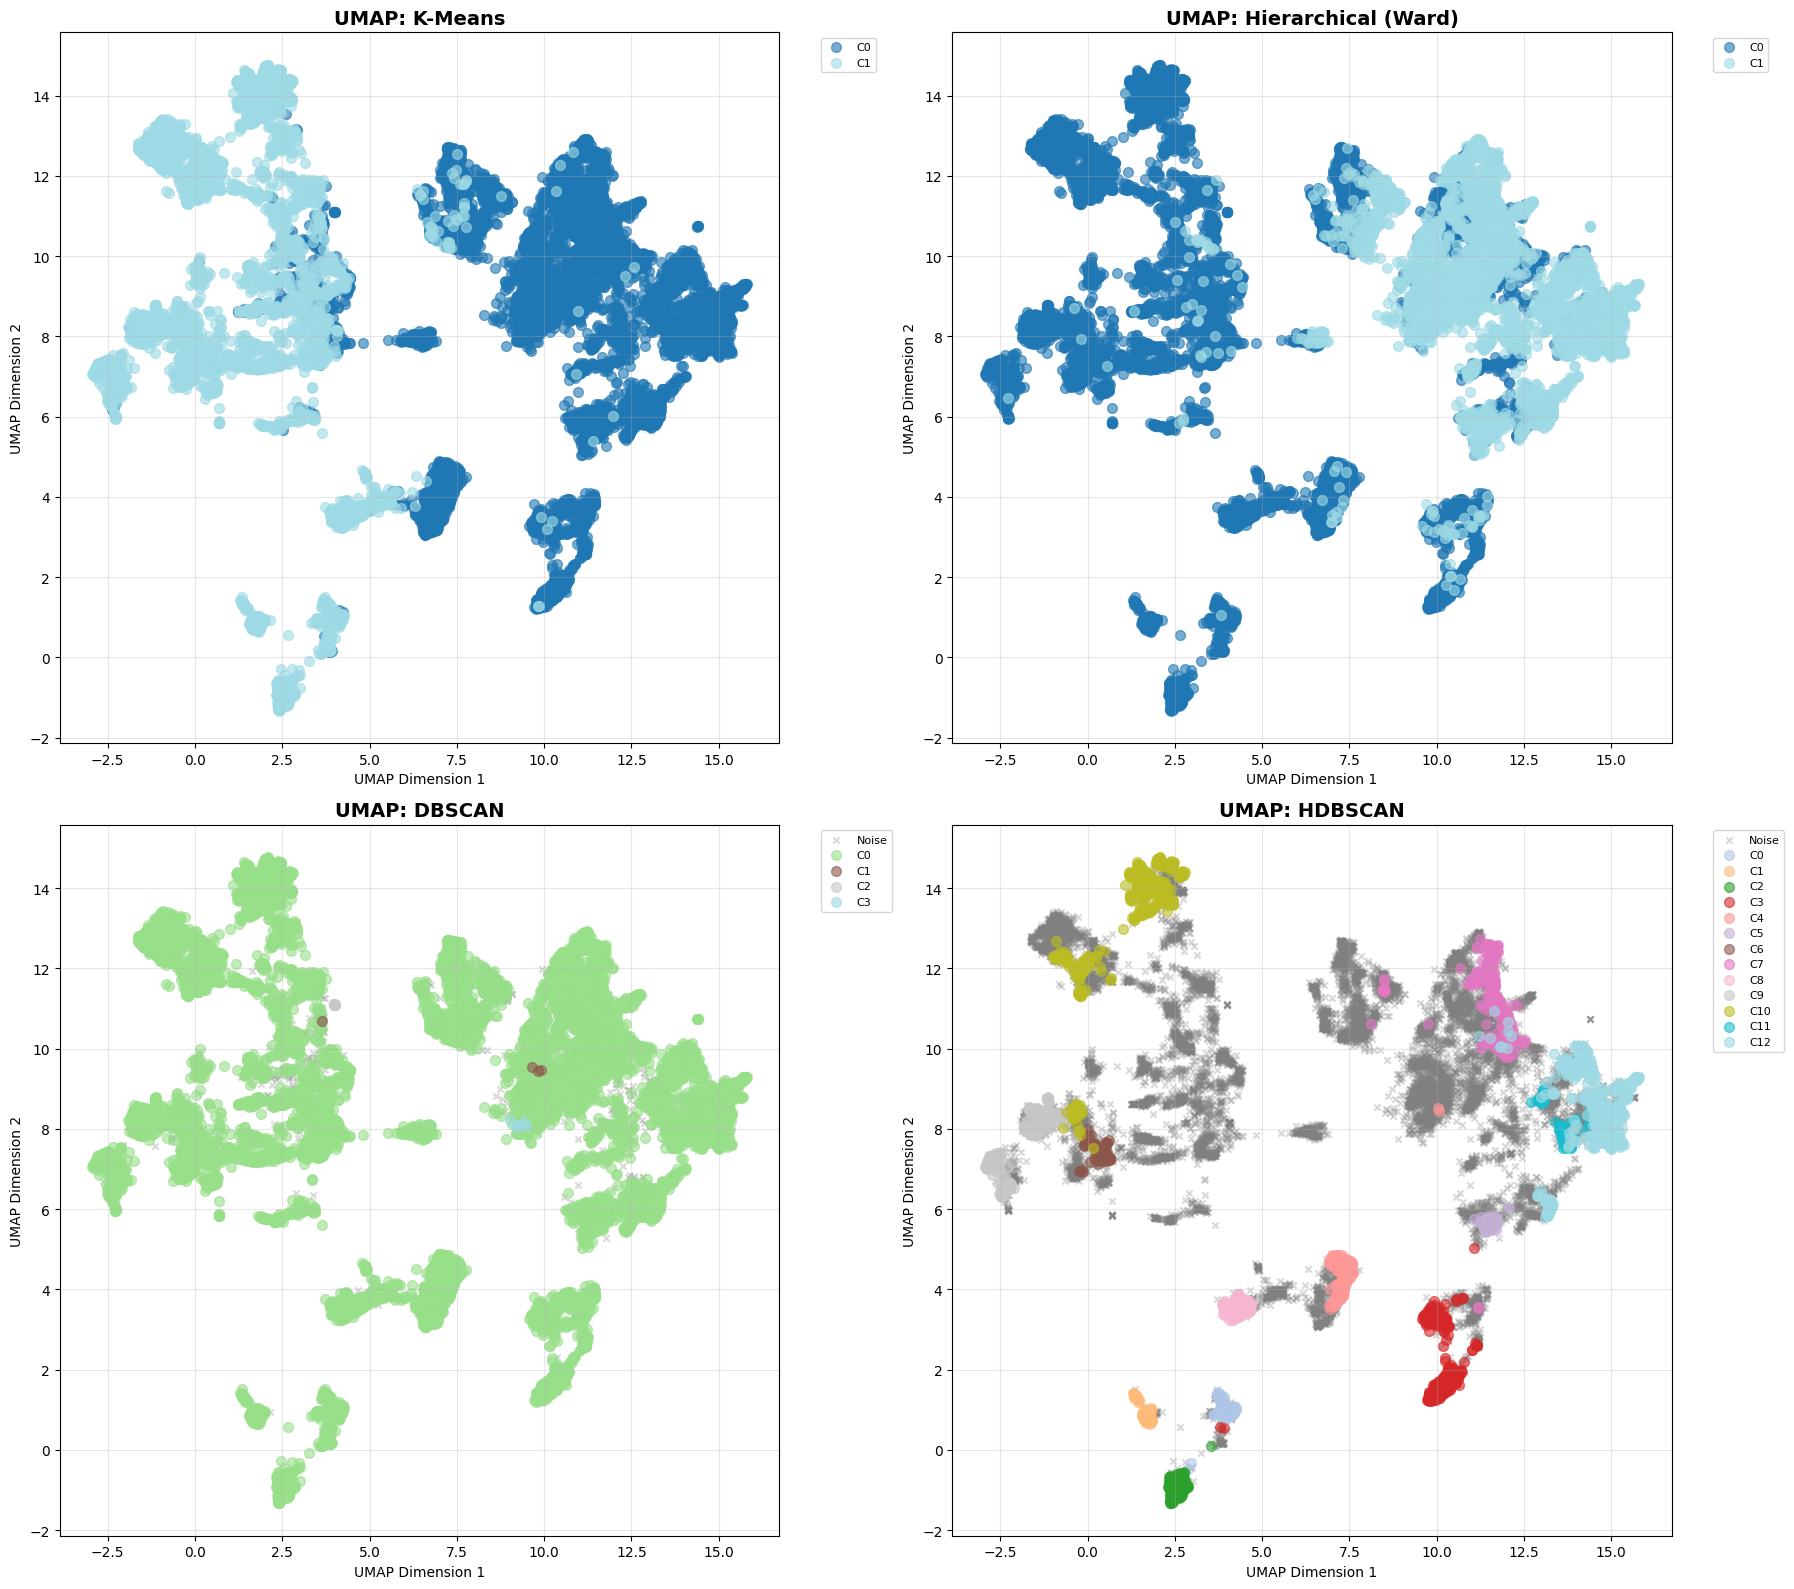

✓ UMAP visualization complete


In [26]:
# ============================================================================
# CELL 16: 2D Visualization with UMAP
# ============================================================================
print("\n" + "=" * 80)
print("2D VISUALIZATION (UMAP)")
print("=" * 80)

import umap

print("Computing UMAP projection...")
umap_model = umap.UMAP(
    n_components=2, random_state=RANDOM_SEED, n_neighbors=15, min_dist=0.1
)
embeddings_umap = umap_model.fit_transform(embeddings_pca)

# Plot each clustering method
fig, axes = plt.subplots(2, 2, figsize=(18, 16))

for idx, (method, labels) in enumerate(zip(methods, labels_list)):
    ax = axes[idx // 2, idx % 2]

    unique_labels = sorted(set(labels))
    colors = plt.cm.tab20(np.linspace(0, 1, len(unique_labels)))

    for label, color in zip(unique_labels, colors):
        mask = labels == label
        if label == -1:
            ax.scatter(
                embeddings_umap[mask, 0],
                embeddings_umap[mask, 1],
                c="gray",
                s=20,
                alpha=0.3,
                label="Noise",
                marker="x",
            )
        else:
            ax.scatter(
                embeddings_umap[mask, 0],
                embeddings_umap[mask, 1],
                c=[color],
                s=50,
                alpha=0.6,
                label=f"C{label}",
            )

    ax.set_title(f"UMAP: {method}", fontsize=14, fontweight="bold")
    ax.set_xlabel("UMAP Dimension 1")
    ax.set_ylabel("UMAP Dimension 2")
    ax.legend(bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=8)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("✓ UMAP visualization complete")


In [27]:
# ============================================================================
# CELL 17: 3D Interactive Visualization (K-Means)
# ============================================================================
print("\n" + "=" * 80)
print("3D INTERACTIVE VISUALIZATION")
print("=" * 80)

# Compute 3D UMAP for best method (K-Means)
umap_3d = umap.UMAP(
    n_components=3, random_state=RANDOM_SEED, n_neighbors=15, min_dist=0.1
)
embeddings_umap_3d = umap_3d.fit_transform(embeddings_pca)

# Create interactive 3D plot
fig = plot_clusters_3d_interactive(
    embeddings_umap_3d,
    labels_hdbscan,
    df,
    title="3D UMAP: K-Means Clustering",
    color_by=None,  # Color by cluster
    hover_cols=["type", "culture", "country", "label"],
)

fig.show()
plt.tight_layout()
plt.show()
print("✓ 3D interactive plot saved as HTML")


3D INTERACTIVE VISUALIZATION


/home/khaledbouabdallah/Projects/llm_grouping_loss_INRIA/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


<Figure size 640x480 with 0 Axes>

✓ 3D interactive plot saved as HTML


In [28]:
# ============================================================================
# CELL 18: Culture & Country Correlation Analysis
# ============================================================================
print("\n" + "=" * 80)
print("CULTURE & COUNTRY CORRELATION ANALYSIS")
print("=" * 80)

# Analyze for K-Means (best method)
grouping_vars = ["culture", "country", "type"]

correlation_results = analyze_cluster_group_correlation(
    labels_kmeans, df, grouping_vars
)

print("\nCorrelation Results:")
print(correlation_results.to_string())

# Interpretation
print("\n" + "-" * 80)
print("INTERPRETATION")
print("-" * 80)
for _, row in correlation_results.iterrows():
    var = row["grouping_variable"]
    cramers = row["cramers_v"]
    effect = row["effect_size"]
    sig = "✓" if row["significant"] else "✗"

    print(f"\n{var}:")
    print(f"  Cramér's V: {cramers:.3f} ({effect} effect) {sig}")
    print(f"  Adjusted Rand Index: {row['adjusted_rand_index']:.3f}")
    print(f"  Normalized Mutual Info: {row['normalized_mutual_info']:.3f}")

2026-01-09 16:30:58,279 - src.analysis.correlation_analysis - INFO - Analyzing correlations for 3 grouping variables
2026-01-09 16:30:58,288 - src.analysis.correlation_analysis - INFO - culture - Cramér's V: 0.377, p-value: 0.0000e+00
2026-01-09 16:30:58,309 - src.analysis.correlation_analysis - INFO - country - Cramér's V: 0.416, p-value: 0.0000e+00
/home/khaledbouabdallah/Projects/llm_grouping_loss_INRIA/src/analysis/correlation_analysis.py:75: RuntimeWarning:

invalid value encountered in divide

2026-01-09 16:30:58,323 - src.analysis.correlation_analysis - INFO - type - Cramér's V: nan, p-value: 1.0000e+00
2026-01-09 16:30:58,330 - src.analysis.correlation_analysis - INFO - Correlation analysis complete for 3 variables



CULTURE & COUNTRY CORRELATION ANALYSIS

Correlation Results:
  grouping_variable  cramers_v  chi2_p_value  significant effect_size  adjusted_rand_index  normalized_mutual_info  n_unique_values
1           country   0.415878           0.0         True       large             0.017469                0.049821               26
0           culture   0.376731           0.0         True       large             0.056543                0.060587                7
2              type        NaN           1.0        False       large             0.000000                0.000000                1

--------------------------------------------------------------------------------
INTERPRETATION
--------------------------------------------------------------------------------

country:
  Cramér's V: 0.416 (large effect) ✓
  Adjusted Rand Index: 0.017
  Normalized Mutual Info: 0.050

culture:
  Cramér's V: 0.377 (large effect) ✓
  Adjusted Rand Index: 0.057
  Normalized Mutual Info: 0.061

type:
  Cramér'


CLUSTER COMPOSITION BY CULTURE


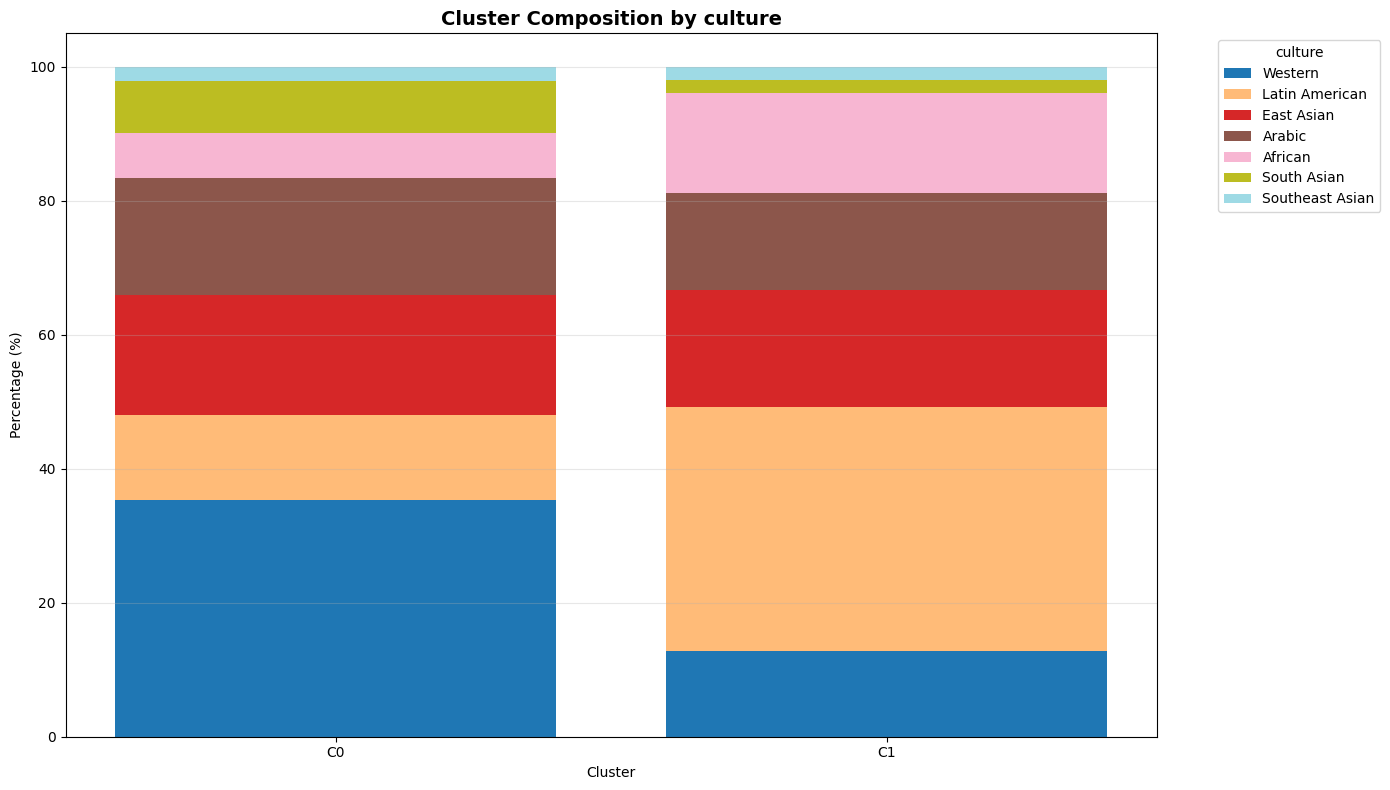

✓ Culture composition plot saved


In [29]:
# ============================================================================
# CELL 19: Cluster Composition by Culture
# ============================================================================
print("\n" + "=" * 80)
print("CLUSTER COMPOSITION BY CULTURE")
print("=" * 80)

fig = plot_cluster_composition(
    labels_kmeans,
    df,
    grouping_var="culture",
    top_n=df["culture"].nunique(),  # Show all cultures
    figsize=(14, 8),
)

plt.show()

print("✓ Culture composition plot saved")


CLUSTER COMPOSITION BY COUNTRY


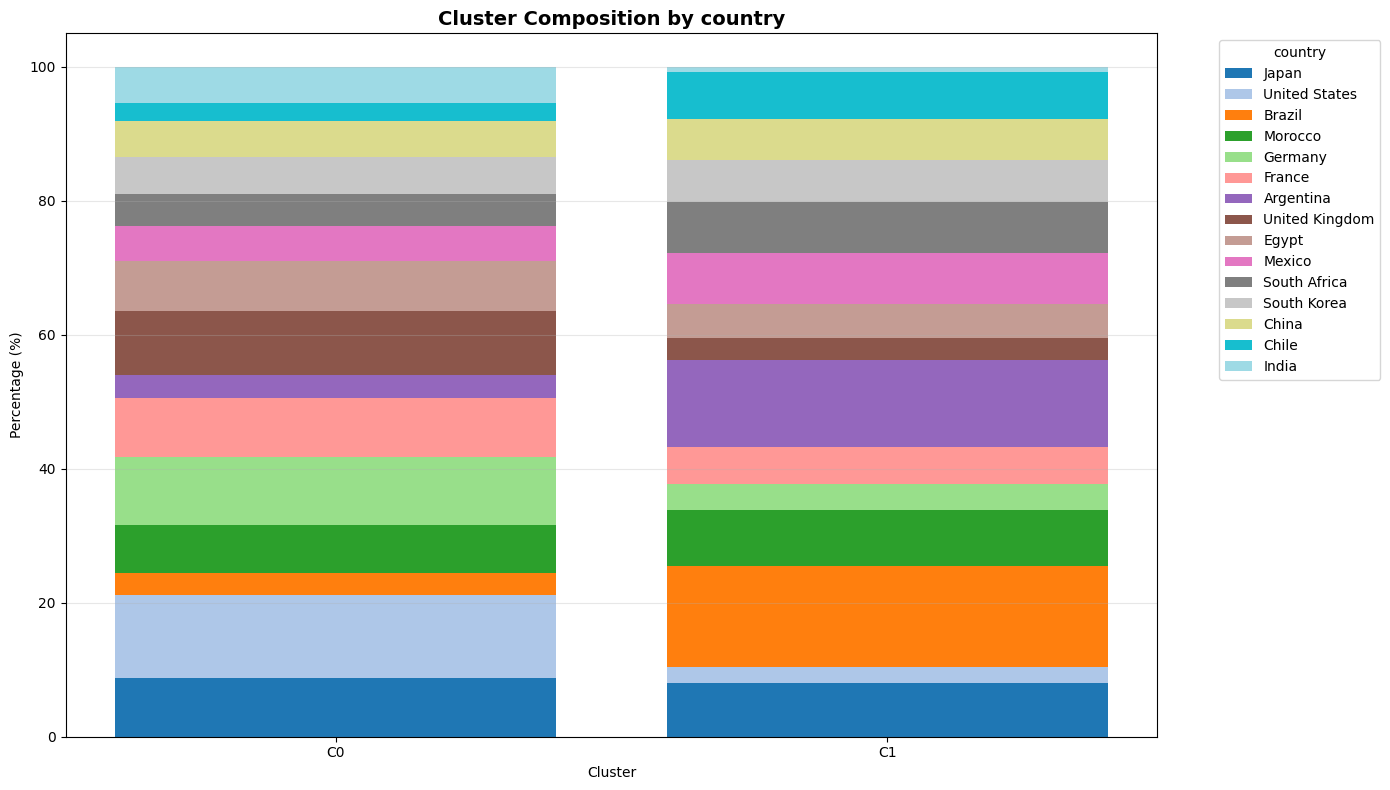

✓ Country composition plot saved


In [30]:
# ============================================================================
# CELL 20: Cluster Composition by Country
# ============================================================================
print("\n" + "=" * 80)
print("CLUSTER COMPOSITION BY COUNTRY")
print("=" * 80)

fig = plot_cluster_composition(
    labels_kmeans,
    df,
    grouping_var="country",
    top_n=15,  # Show top 15 countries
    figsize=(14, 8),
)

plt.show()

print("✓ Country composition plot saved")

In [31]:
# ============================================================================
# CELL 21: Purity Analysis
# ============================================================================
print("\n" + "=" * 80)
print("CLUSTER PURITY ANALYSIS")
print("=" * 80)

for var in ["culture", "country"]:
    print(f"\n{var.upper()} Purity:")
    print("-" * 40)

    purity_results = analyze_cluster_purity(labels_kmeans, df, var)

    print(f"Overall statistics:")
    for stat, value in purity_results["overall_stats"].items():
        print(f"  {stat}: {value:.3f}")

    print(f"\nPer cluster:")
    for cluster_id, stats in sorted(purity_results["per_cluster"].items()):
        print(
            f"  Cluster {cluster_id}: purity={stats['purity']:.3f}, "
            f"dominant={stats['dominant_value']} ({stats['dominant_count']}/{stats['total_count']})"
        )


CLUSTER PURITY ANALYSIS

CULTURE Purity:
----------------------------------------
Overall statistics:
  mean_purity: 0.359
  std_purity: 0.005
  min_purity: 0.354
  max_purity: 0.364
  median_purity: 0.359

Per cluster:
  Cluster 0: purity=0.354, dominant=Western (4794/13550)
  Cluster 1: purity=0.364, dominant=Latin American (3440/9457)

COUNTRY Purity:
----------------------------------------
Overall statistics:
  mean_purity: 0.117
  std_purity: 0.010
  min_purity: 0.107
  max_purity: 0.128
  median_purity: 0.117

Per cluster:
  Cluster 0: purity=0.107, dominant=United States (1449/13550)
  Cluster 1: purity=0.128, dominant=Brazil (1209/9457)


2026-01-09 16:30:58,513 - src.analysis.correlation_analysis - INFO - Analyzing hierarchical split order for ['country', 'culture']



HIERARCHICAL SPLIT ORDER: COUNTRIES vs CULTURES

Purity by depth:
----------------------------------------
n_clusters=2:
  country: 0.124
  culture: 0.382
n_clusters=3:
  country: 0.183
  culture: 0.474
n_clusters=4:
  country: 0.233
  culture: 0.561
n_clusters=5:
  country: 0.227
  culture: 0.546
n_clusters=6:
  country: 0.362
  culture: 0.615
n_clusters=7:
  country: 0.371
  culture: 0.651
n_clusters=8:
  country: 0.352
  culture: 0.623
n_clusters=9:
  country: 0.421
  culture: 0.662
n_clusters=10:
  country: 0.424
  culture: 0.709

----------------------------------------
EARLY SPLIT RANKING:
----------------------------------------
  culture: 0.472
  country: 0.180

Hierarchical clustering tends to split by 'culture' first


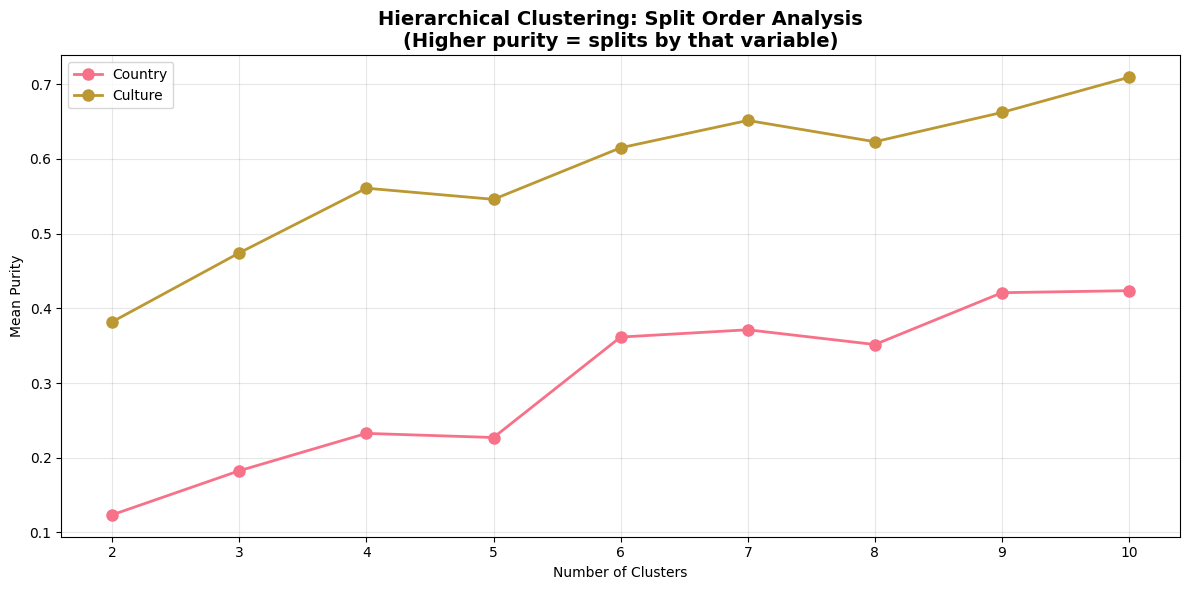

In [32]:
# ============================================================================
# CELL 22: Hierarchical Split Order Analysis
# ============================================================================
print("\n" + "=" * 80)
print("HIERARCHICAL SPLIT ORDER: COUNTRIES vs CULTURES")
print("=" * 80)

split_order_results = test_hierarchical_split_order(
    embeddings_pca,
    df,
    grouping_vars=["country", "culture"],
    method="ward",
    max_depth=10,
)

print("\nPurity by depth:")
print("-" * 40)
for depth, purities in sorted(split_order_results["purity_by_depth"].items()):
    print(f"n_clusters={depth}:")
    for var, purity in purities.items():
        print(f"  {var}: {purity:.3f}")

print("\n" + "-" * 40)
print("EARLY SPLIT RANKING:")
print("-" * 40)
for var, avg_purity in split_order_results["early_split_ranking"]:
    print(f"  {var}: {avg_purity:.3f}")

print("\n" + "=" * 80)
print(split_order_results["interpretation"])
print("=" * 80)

# Visualize split order
fig, ax = plt.subplots(figsize=(12, 6))

for var in ["country", "culture"]:
    depths = sorted(split_order_results["purity_by_depth"].keys())
    purities = [split_order_results["purity_by_depth"][d][var] for d in depths]
    ax.plot(depths, purities, "o-", linewidth=2, markersize=8, label=var.capitalize())

ax.set_xlabel("Number of Clusters")
ax.set_ylabel("Mean Purity")
ax.set_title(
    "Hierarchical Clustering: Split Order Analysis\n(Higher purity = splits by that variable)",
    fontsize=14,
    fontweight="bold",
)
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [33]:
# ============================================================================
# CELL 23: Contingency Tables
# ============================================================================
print("\n" + "=" * 80)
print("CONTINGENCY TABLES")
print("=" * 80)

# Culture contingency table
print("\nCluster × Culture:")
contingency_culture = calculate_contingency_table(labels_kmeans, df, "culture")
print(contingency_culture)

# Country contingency table (top countries only)
print("\nCluster × Country (top 10):")
top_countries = df["country"].value_counts().head(10).index
df_top_countries = df[df["country"].isin(top_countries)]
labels_top_countries = labels_kmeans[df["country"].isin(top_countries)]
contingency_country = calculate_contingency_table(
    labels_top_countries, df_top_countries, "country"
)
print(contingency_country)


CONTINGENCY TABLES

Cluster × Culture:
culture  African  Arabic  East Asian  Latin American  South Asian  \
cluster                                                             
0            908    2354        2439            1710         1067   
1           1421    1360        1657            3440          180   
Total       2329    3714        4096            5150         1247   

culture  Southeast Asian  Western  Total  
cluster                                   
0                    278     4794  13550  
1                    183     1216   9457  
Total                461     6010  23007  

Cluster × Country (top 10):
country  Argentina  Brazil  Egypt  France  Germany  Japan  Mexico  Morocco  \
cluster                                                                      
0              404     380    873    1037     1180   1027     604      849   
1             1047    1209    402     443      307    639     611      665   
Total         1451    1589   1275    1480     1487   1666 

In [34]:
# ============================================================================
# CELL 24: TF-IDF Keywords Extraction
# ============================================================================
print("\n" + "=" * 80)
print("TF-IDF KEYWORDS PER CLUSTER")
print("=" * 80)

# Load Wikipedia texts for keyword extraction
db = EntityDatabase("../data/entities.db")

# Prepare texts for each entity
texts = []
for _, row in tqdm(df.iterrows(), total=len(df), desc="Loading Wikipedia texts"):
    wiki_texts = db.get_wikipedia_texts(row["id"])

    # Combine texts from all languages
    combined_text = ""
    for lang in ["en", "fr", "ar"]:
        if lang in wiki_texts and wiki_texts[lang]["summary"]:
            combined_text += " " + wiki_texts[lang]["summary"]

    # Fallback to label if no text
    if not combined_text.strip():
        combined_text = row["label"]

    texts.append(combined_text.strip())

print(f"✓ Loaded {len(texts)} texts")

# Extract keywords
keywords_by_cluster = extract_tfidf_keywords(
    texts, labels_kmeans, n_keywords=10, ngram_range=(1, 3), min_df=2, max_df=0.7
)

print("\nTop Keywords by Cluster:")
print("=" * 80)
for cluster_id in sorted(keywords_by_cluster.keys()):
    keywords = keywords_by_cluster[cluster_id]
    n_entities = (labels_kmeans == cluster_id).sum()
    print(f"\nCluster {cluster_id} ({n_entities} entities):")
    print(f"  {', '.join(keywords)}")

2026-01-09 16:31:13,951 - src.data.database - INFO - Database initialized at ../data/entities.db



TF-IDF KEYWORDS PER CLUSTER


Loading Wikipedia texts: 100%|██████████| 23007/23007 [00:01<00:00, 11780.31it/s]
2026-01-09 16:31:15,909 - src.clustering.cluster_methods - INFO - Extracting TF-IDF keywords for 2 clusters


✓ Loaded 23007 texts


2026-01-09 16:31:29,429 - src.clustering.cluster_methods - INFO - Keyword extraction complete for 2 clusters



Top Keywords by Cluster:

Cluster 0 (13550 entities):
  he, was, en, il, his, du, she, des, born, her

Cluster 1 (9457 entities):
  he, en, il, مع, au, was, du, ونادي, كرة قدم, لاعب كرة


In [35]:
# ============================================================================
# CELL 25: Cluster Summary Report
# ============================================================================
print("\n" + "=" * 80)
print("CLUSTER SUMMARY REPORT")
print("=" * 80)

for cluster_id in sorted(set(labels_kmeans)):
    mask = labels_kmeans == cluster_id
    cluster_df = df[mask]

    print(f"\n{'='*80}")
    print(f"CLUSTER {cluster_id}")
    print(f"{'='*80}")

    print(f"\nSize: {len(cluster_df)} entities ({100*len(cluster_df)/len(df):.1f}%)")

    print(f"\nEntity Types:")
    for etype, count in cluster_df["type"].value_counts().head(5).items():
        print(f"  {etype}: {count} ({100*count/len(cluster_df):.1f}%)")

    print(f"\nCultures:")
    for culture, count in cluster_df["culture"].value_counts().items():
        print(f"  {culture}: {count} ({100*count/len(cluster_df):.1f}%)")

    print(f"\nTop Countries:")
    for country, count in cluster_df["country"].value_counts().head(5).items():
        print(f"  {country}: {count} ({100*count/len(cluster_df):.1f}%)")

    print(f"\nKeywords:")
    keywords = keywords_by_cluster.get(cluster_id, [])
    print(f"  {', '.join(keywords[:10])}")

    print(f"\nSample Entities:")
    for i, (_, entity) in enumerate(cluster_df.head(5).iterrows(), 1):
        print(f"  {i}. {entity['label']} ({entity['type']}, {entity['country']})")


CLUSTER SUMMARY REPORT

CLUSTER 0

Size: 13550 entities (58.9%)

Entity Types:
  person: 13550 (100.0%)

Cultures:
  Western: 4794 (35.4%)
  East Asian: 2439 (18.0%)
  Arabic: 2354 (17.4%)
  Latin American: 1710 (12.6%)
  South Asian: 1067 (7.9%)
  African: 908 (6.7%)
  Southeast Asian: 278 (2.1%)

Top Countries:
  United States: 1449 (10.7%)
  Germany: 1180 (8.7%)
  United Kingdom: 1128 (8.3%)
  France: 1037 (7.7%)
  Japan: 1027 (7.6%)

Keywords:
  he, was, en, il, his, du, she, des, born, her

Sample Entities:
  1. Dwayne Johnson (person, United States)
  2. Mick Foley (person, United States)
  3. Bill Clinton (person, United States)
  4. Madonna (person, United States)
  5. Jimmy Bennett (person, United States)

CLUSTER 1

Size: 9457 entities (41.1%)

Entity Types:
  person: 9457 (100.0%)

Cultures:
  Latin American: 3440 (36.4%)
  East Asian: 1657 (17.5%)
  African: 1421 (15.0%)
  Arabic: 1360 (14.4%)
  Western: 1216 (12.9%)
  Southeast Asian: 183 (1.9%)
  South Asian: 180 (1.9%)


In [36]:

# ============================================================================
# CELL 26: Save Results
# ============================================================================
print("\n" + "=" * 80)
print("SAVING RESULTS")
print("=" * 80)

# Save DataFrame with cluster assignments
output_file = "../data/experiment/entities_with_clusters.csv"
df.to_csv(output_file, index=False)
print(f"✓ Saved entities with cluster assignments: {output_file}")

# Save clustering comparison
comparison_file = "../data/experiment/clustering_comparison.csv"
comparison_df.to_csv(comparison_file, index=False)
print(f"✓ Saved clustering comparison: {comparison_file}")

# Save correlation analysis
correlation_file = "../data/experiment/cluster_correlation_analysis.csv"
correlation_results.to_csv(correlation_file, index=False)
print(f"✓ Saved correlation analysis: {correlation_file}")

# Save keywords
import json

keywords_file = "../data/experiment/cluster_keywords.json"
with open(keywords_file, "w", encoding="utf-8") as f:
    json.dump(keywords_by_cluster, f, ensure_ascii=False, indent=2)
print(f"✓ Saved cluster keywords: {keywords_file}")

print("\n" + "=" * 80)
print("CLUSTERING ANALYSIS COMPLETE")
print("=" * 80)
print("\nSummary:")
print(f"  Best method: K-Means with k={optimal_k}")
print(f"  Total entities: {len(df)}")
print(f"  Number of clusters: {len(set(labels_kmeans))}")
print(
    f"  Culture correlation: {correlation_results[correlation_results['grouping_variable']=='culture']['cramers_v'].values[0]:.3f}"
)
print(
    f"  Country correlation: {correlation_results[correlation_results['grouping_variable']=='country']['cramers_v'].values[0]:.3f}"
)
print(f"\nAll results saved to: ../data/experiment/ and ../data/results_resumes/")



SAVING RESULTS
✓ Saved entities with cluster assignments: ../data/experiment/entities_with_clusters.csv
✓ Saved clustering comparison: ../data/experiment/clustering_comparison.csv
✓ Saved correlation analysis: ../data/experiment/cluster_correlation_analysis.csv
✓ Saved cluster keywords: ../data/experiment/cluster_keywords.json

CLUSTERING ANALYSIS COMPLETE

Summary:
  Best method: K-Means with k=2
  Total entities: 23007
  Number of clusters: 2
  Culture correlation: 0.377
  Country correlation: 0.416

All results saved to: ../data/experiment/ and ../data/results_resumes/
